In [1]:
!pip install langgraph
!pip install langchain_groq
!pip install dotenv

In [2]:
from langgraph.graph import StateGraph, START,END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import  ChatOpenAI
from langchain_core.prompts import ChatMessagePromptTemplate
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [3]:
load_dotenv()

True

In [ ]:
llm= ChatGroq(model="openai/gpt-oss-120b")

AIMessage(content='A diffusion model is a type of generative model that learns to create data—such as images, audio, or text—by progressively destroying and then reconstructing information. \n\nThe core idea is inspired by thermodynamics: imagine a drop of ink in a glass of water. Over time, the ink diffuses and spreads until it is uniformly distributed, creating a murky, featureless liquid. A diffusion model learns to reverse this process. \n\nHere’s how it works in two main phases:\n\n**1. The Forward Process (Adding Noise)**\nDuring training, the model takes a clean piece of data (e.g., a picture of a cat) and gradually adds random Gaussian noise to it over many steps. Step by step, the image becomes grainier and less recognizable until it is pure, static-like noise. This process is deterministic and simple—it just corrupts the data.\n\n**2. The Reverse Process (Denoising)**\nThe model then learns to reverse this corruption. Starting from pure noise, it is trained to predict and rem

In [5]:
from langgraph.graph.message import add_messages
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage],add_messages]

In [6]:
def chat_node(state: ChatState):
 # take query from state
  messages = state['messages']
 #send to llm 
  response = llm.invoke(messages)
 # response store state
  return {'messages': [response]}  


In [ ]:

checkpoint = MemorySaver()

graph= StateGraph(ChatState)
# Lets add nodes
graph.add_node('chat_node', chat_node)

# add edges

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node' ,END)


chatbot = graph.compile(checkpointer=checkpoint)

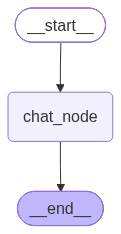

In [8]:
chatbot

In [9]:
# initial_message = {
#     'messages' :[HumanMessage(content="What is object oriented programming in one line? ") ]
# }

# response = chatbot.invoke(initial_message)

In [10]:
# response['messages'][-1].content

In [12]:
thread_id = "1"


while True:
    user_message = input('Type here: ')
    print('User:' , user_message)

    if user_message.strip().lower() in ['exit', 'quit' , 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI:', response['messages'][-1].content)

User: hi
AI: Hello! How can I help you today?
User: me ashish
AI: Nice to meet you, Ashish! How can I assist you today?
User: what is persistece?
AI: **Persistence** (sometimes misspelled as “persistece”) is the quality of continuing steadily toward a goal, even in the face of obstacles, setbacks, or fatigue. It shows up in many fields, so let’s break it down a few common contexts:

| Context | What “persistence” means | Everyday example |
|---------|--------------------------|-------------------|
| **Psychology / Personal development** | The ability to keep trying, stay motivated, and maintain effort over time despite difficulties. | Studying for a professional exam for months, even when the material feels overwhelming. |
| **Computer science / Programming** | Storing data so that it outlives the process that created it. In other words, “making something persistent” means writing it to a non‑volatile medium (disk, database, cloud storage) so it can be retrieved later. | Saving a user’

In [13]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='1a175d8c-bdf1-4138-8bbc-1a401c434b8b'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user said "hi". Simple greeting. Follow guidelines. Should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.082820821, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.002978283, 'prompt_tokens_details': None, 'queue_time': 0.393947088, 'total_time': 0.085799104}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18b0f-ead2-71f6-b95b-0b706ffdd1d4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_t